## Interval Analysis

In [1]:
!pip install tensorboardX


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 2.9 MB/s eta 0:00:00


In [2]:
!pip install torch

In [3]:
!pip install matplotlib

In [4]:
!pip install torchvision

In [ ]:
!pip install --upgrade torch torchvision --index-url https://download.pytorch.org/whl/cu128

Looking in indexes: https://download.pytorch.org/whl/cu128


In [6]:

import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("PyTorch location:", torch.__file__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())


Python: /usr/bin/python3
PyTorch: 2.11.0+cpu
PyTorch location: /usr/local/lib/python3.13/dist-packages/torch/__init__.py
CUDA build: None
CUDA available: False


In [ ]:
%pip uninstall -y torch torchvision
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu128

Found existing installation: torch 2.14.1
Uninstalling torch-2.14.1:
  Successfully uninstalled torch-2.14.1
Found existing installation: torchvision 0.29.1
Uninstalling torchvision-0.29.1:
  Successfully uninstalled torchvision-0.29.1
Note: you may need to restart the kernel to use updated packages.
Looking in indexes: https://download.pytorch.org/whl/cu128
  Using cached torch-2.11.0%2Bcu128-cp313-cp313-manylinux_2_28_x86_64.whl.metadata (29 kB)
  Using cached torchvision-0.26.0%2Bcu128-cp313-cp313-manylinux_2_28_x86_64.whl.metadata (5.5 kB)
  Using cached setuptools-78.1.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached cuda_bindings-12.9.7-cp313-cp313-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (2.6 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 657.9/657.9 MB 81.0 MB/s  0:00:07:00:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 287.2/287.2 MB 136.0 MB/s  0:00:0200:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.8/296.8 MB 85.2 MB/s  0:00:03:00:010

In [ ]:
import torch

print(torch.__version__)
print(torch.version.cuda)
print(torch.cuda.is_available())

2.11.0+cu128
12.8
True


In [7]:


import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


100%|██████████| 9.91M/9.91M [00:00<00:00, 131MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 9.64MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 23.8MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.60MB/s]


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [8]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

In [9]:
train_model(model, 15)
test_model(model)

Epoch 1/15, Loss: 2.012
Epoch 2/15, Loss: 1.729
Epoch 3/15, Loss: 1.627
Epoch 4/15, Loss: 1.596
Epoch 5/15, Loss: 1.582
Epoch 6/15, Loss: 1.572
Epoch 7/15, Loss: 1.566
Epoch 8/15, Loss: 1.561
Epoch 9/15, Loss: 1.557
Epoch 10/15, Loss: 1.553
Epoch 11/15, Loss: 1.550
Epoch 12/15, Loss: 1.547
Epoch 13/15, Loss: 1.545
Epoch 14/15, Loss: 1.542
Epoch 15/15, Loss: 1.540
Accuracy on images: 93.43


### Write the interval analysis for the simple model

In [10]:
## TODO: Write the interval analysis for the simple model
## you can use https://github.com/Zinoex/bound_propagation

def linear_bounds(layer, lower, upper):
    W = layer.weight
    b = layer.bias
    W_pos = torch.clamp(W, min=0)
    W_neg = torch.clamp(W, max=0)
    new_lower = lower @ W_pos.T + upper @ W_neg.T + b
    new_upper = upper @ W_pos.T + lower @ W_neg.T + b
    return new_lower, new_upper


def verify_batch(model, images, labels, eps):
    net = model[1]
    images = images.view(-1, 28*28)

    lower = torch.clamp(images - eps, 0, 1)
    upper = torch.clamp(images + eps, 0, 1)

    # normalize layer
    lower = (lower - 0.1307) / 0.3081
    upper = (upper - 0.1307) / 0.3081

    lower, upper = linear_bounds(net.fc, lower, upper)
    lower = torch.relu(lower)
    upper = torch.relu(upper)

    # output layer
    lower, upper = linear_bounds(net.fc2, lower, upper)

    verified = []
    for i in range(len(labels)):
        y = labels[i].item()
        ok = True
        for j in range(10):
            if j == y:
                continue
            if lower[i, y] - upper[i, j] < 0:
                ok = False
                break
        verified.append(ok)
    return verified


def verified_accuracy(model, eps):
    model.eval()
    count = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            preds = model(images).argmax(dim=1)
            verified = verify_batch(model, images, labels, eps)
            for i in range(len(labels)):
                # only count if it's also classified correctly
                if verified[i] and preds[i] == labels[i]:
                    count += 1
            total += len(labels)
    return 100 * count / total

eps = 0.01, verified accuracy = 49.59%
eps = 0.02, verified accuracy = 5.30%
eps = 0.03, verified accuracy = 0.20%
eps = 0.04, verified accuracy = 0.00%
eps = 0.05, verified accuracy = 0.00%
eps = 0.06, verified accuracy = 0.00%
eps = 0.07, verified accuracy = 0.00%
eps = 0.08, verified accuracy = 0.00%
eps = 0.09, verified accuracy = 0.00%
eps = 0.10, verified accuracy = 0.00%


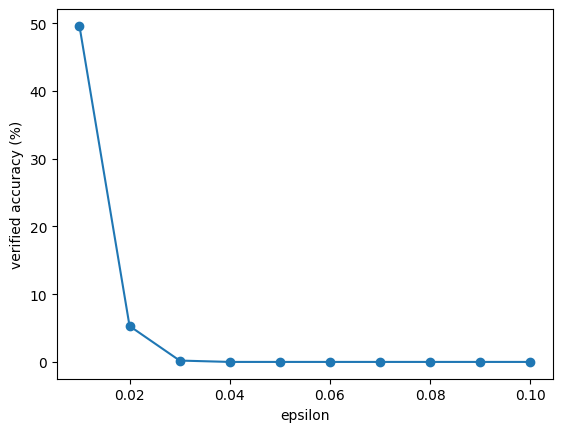

In [11]:
epsilons = np.linspace(0.01, 0.1, 10)
accs = []

for eps in epsilons:
    acc = verified_accuracy(model, eps)
    accs.append(acc)
    print(f"eps = {eps:.2f}, verified accuracy = {acc:.2f}%")

plt.plot(epsilons, accs, 'o-')
plt.xlabel("epsilon")
plt.ylabel("verified accuracy (%)")
plt.show()